# 03. 모델 학습 — 로지스틱 회귀 vs LightGBM

| 모델 | 역할 | 전처리 |
|---|---|---|
| 로지스틱 회귀 (L2, class_weight) | 기준점. 복잡한 모델이 정말 필요한지 판단 | 중앙값 대체 + 클리핑 + 표준화 |
| LightGBM (class_weight) | 주력. 비선형 관계, 결측을 직접 처리 | 결측 유지 |

진행 순서
1. **학습 데이터 안에서만** 시간순 교차검증으로 설정값을 고른다
2. 고른 설정으로 학습 데이터 전체를 다시 학습한다
3. 평가 데이터로 **한 번만** 채점한다
4. 무작위 분할로 했다면 점수가 어떻게 나왔을지 비교한다

모델 정의와 설정 후보는 `src/models.py`에 있다.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split

from src.data import load_secom, time_split
from src.models import build_logistic, build_lightgbm, tune, LOGISTIC_GRID, LIGHTGBM_GRID

sns.set_theme(style="whitegrid")
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"

X, y, ts = load_secom()
X_train, X_test, y_train, y_test = time_split(X, y)
print(f"train {X_train.shape}, 불량 {y_train.sum()} / test {X_test.shape}, 불량 {y_test.sum()}")

train (1175, 590), 불량 80 / test (392, 590), 불량 24


## 1. 기준선: 아무렇게나 찍으면 PR-AUC는 몇인가

PR-AUC의 무작위 기준선은 **불량 비율**과 같다. 모델 점수는 항상 이 숫자와 비교해서 읽는다.

In [2]:
random_baseline = y_test.mean()
print(f"test 불량 비율 = 무작위 PR-AUC 기준선 = {random_baseline:.3f}")

test 불량 비율 = 무작위 PR-AUC 기준선 = 0.061


## 2. 시간순 교차검증으로 설정값 고르기

`TimeSeriesSplit(4)`는 학습 데이터를 시간순으로 5등분하고, 다음처럼 4번 검증한다.

```
fold 1: [학습        ][검증]
fold 2: [학습              ][검증]
fold 3: [학습                    ][검증]
fold 4: [학습                          ][검증]
```

항상 과거로 학습하고 바로 다음 시기로 검증한다. test는 여기서 쓰지 않는다.

In [3]:
lr_search = tune(build_logistic(), LOGISTIC_GRID, X_train, y_train)
gb_search = tune(build_lightgbm(), LIGHTGBM_GRID, X_train, y_train)

def indicator_label(v):
    return "off" if isinstance(v, str) and v == "passthrough" else "on"

def readable(params):
    return {k.replace("model__", "").replace("prep__", ""): (indicator_label(v) if k == "prep__missing_flags" else v)
            for k, v in params.items()}

def cv_table(search, top=5):
    res = pd.DataFrame(search.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")]
    folds = [f"split{i}_test_score" for i in range(4)]
    out = res[cols + ["mean_test_score", "std_test_score"] + folds].sort_values("mean_test_score", ascending=False)
    out.columns = [c.replace("param_", "").replace("model__", "").replace("prep__", "") for c in out.columns]
    out["missing_flags"] = out["missing_flags"].map(indicator_label)
    out = out.rename(columns={"mean_test_score": "CV 평균", "std_test_score": "CV 표준편차",
                              **{f"split{i}_test_score": f"fold{i+1}" for i in range(4)}})
    return out.head(top).round(3)

print("로지스틱 회귀 상위 설정")
display(cv_table(lr_search))
print("LightGBM 상위 설정")
display(cv_table(gb_search))

로지스틱 회귀 상위 설정


,C,missing_flags,CV 평균,CV 표준편차,fold1,fold2,fold3,fold4
3,0.010,on,0.076,0.036,0.100,0.089,0.099,0.014
5,0.100,on,0.071,0.032,0.101,0.084,0.083,0.018
4,0.100,off,0.071,0.038,0.105,0.107,0.057,0.016
2,0.010,off,0.067,0.033,0.104,0.086,0.064,0.015
1,0.001,on,0.067,0.035,0.106,0.057,0.090,0.015


LightGBM 상위 설정


,colsample_bytree,max_depth,missing_flags,CV 평균,CV 표준편차,fold1,fold2,fold3,fold4
0,0.1,2,off,0.174,0.194,0.143,0.037,0.500,0.019
3,0.1,3,on,0.174,0.187,0.148,0.038,0.488,0.022
5,0.3,2,on,0.171,0.191,0.137,0.037,0.493,0.019
1,0.1,2,on,0.163,0.165,0.155,0.042,0.435,0.019
2,0.1,3,off,0.163,0.171,0.145,0.038,0.447,0.022


In [4]:
from sklearn.model_selection import TimeSeriesSplit
fold_info = pd.DataFrame([
    {"fold": i + 1, "학습 행": len(tr), "검증 행": len(va), "검증 불량 수": int(y_train.iloc[va].sum())}
    for i, (tr, va) in enumerate(TimeSeriesSplit(4).split(X_train))
])
fold_info

,fold,학습 행,검증 행,검증 불량 수
0,1,235,235,26
1,2,470,235,8
2,3,705,235,10
3,4,940,235,4


**해석**
- 검증 구간마다 불량이 **4~26개**밖에 없다. 불량 몇 개를 맞히고 못 맞히는 것으로 PR-AUC가 크게 흔들린다.
- 특히 LightGBM은 fold별 점수 차이가 크다(어떤 fold는 0.4, 어떤 fold는 0.03).
  평균만 보고 "LightGBM이 낫다"고 결론 내리면 위험하다 → **표준편차를 같이 봐야** 한다.
- 결측 지시자(`missing_flags`)는 위 표에서 켜진 설정과 꺼진 설정이 섞여 있다. 일관된 이득은 보이지 않는다.

## 3. 평가 데이터로 한 번 채점

In [5]:
models = {"로지스틱 회귀": lr_search.best_estimator_, "LightGBM": gb_search.best_estimator_}
rows = []
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    search = lr_search if name == "로지스틱 회귀" else gb_search
    rows.append({"모델": name,
                 "CV PR-AUC (평균±표준편차)": f"{search.best_score_:.3f} ± {search.cv_results_['std_test_score'][search.best_index_]:.3f}",
                 "test PR-AUC": average_precision_score(y_test, proba),
                 "test ROC-AUC": roc_auc_score(y_test, proba),
                 "무작위 대비 배수": average_precision_score(y_test, proba) / random_baseline})
result = pd.DataFrame(rows).set_index("모델").round(3)
result

,CV PR-AUC (평균±표준편차),test PR-AUC,test ROC-AUC,무작위 대비 배수
모델,,,,
로지스틱 회귀,0.076 ± 0.036,0.097,0.669,1.580
LightGBM,0.174 ± 0.194,0.073,0.539,1.198


In [6]:
best_params = {"logistic": readable(lr_search.best_params_), "lightgbm": readable(gb_search.best_params_)}
(REPORT_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2, ensure_ascii=False))
result.to_csv(REPORT_DIR / "model_comparison.csv", encoding="utf-8-sig")
best_params

{'logistic': {'C': 0.01, 'missing_flags': 'on'},
 'lightgbm': {'colsample_bytree': 0.1, 'max_depth': 2, 'missing_flags': 'off'}}

**해석**
- 두 모델 모두 무작위(약 0.06)보다는 낫지만, 차이가 크지 않다. **SECOM은 원래 예측이 어려운 데이터**다.
  센서 이름이 지워져 도메인 지식을 쓸 수 없고, 불량이 적고, 시기에 따라 공정이 바뀐다.
- **CV에서는 LightGBM이 앞섰지만 test에서는 그 우위가 유지되지 않았다.**
  CV 표준편차가 컸던 것과 같은 이야기다. 불량 80개로 수백 그루 나무를 학습하면, 과거 특정 시기의 패턴을 외울 위험이 크다.
- 그래서 "복잡한 모델이 항상 낫다"가 아니라, **데이터가 작고 시기가 변할 때는 단순한 모델이 더 안정적일 수 있다**는 것이 이 단계의 결론이다.

## 4. 무작위 분할로 했다면?

많은 SECOM 예제가 데이터를 무작위로 섞어서 나눈다. 같은 모델 설정으로 무작위 분할(층화, 5번 반복) 점수를 계산해 비교한다.

In [7]:
def random_split_scores(build, n_seeds=5):
    scores = []
    for seed in range(n_seeds):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
        m = build().fit(Xa, ya)
        scores.append(average_precision_score(yb, m.predict_proba(Xb)[:, 1]))
    return np.mean(scores), np.std(scores)

builders = {
    "로지스틱 회귀": lambda: build_logistic().set_params(**lr_search.best_params_),
    "LightGBM": lambda: build_lightgbm().set_params(**gb_search.best_params_),
}
rows = []
for name, build in builders.items():
    mean, std = random_split_scores(build)
    rows.append({"모델": name, "무작위 분할 PR-AUC": f"{mean:.3f} ± {std:.3f}",
                 "시간순 분할 PR-AUC": f"{result.loc[name, 'test PR-AUC']:.3f}"})
split_cmp = pd.DataFrame(rows).set_index("모델")
split_cmp.to_csv(REPORT_DIR / "split_comparison.csv", encoding="utf-8-sig")
split_cmp

,무작위 분할 PR-AUC,시간순 분할 PR-AUC
모델,,
로지스틱 회귀,0.149 ± 0.032,0.097
LightGBM,0.175 ± 0.041,0.073


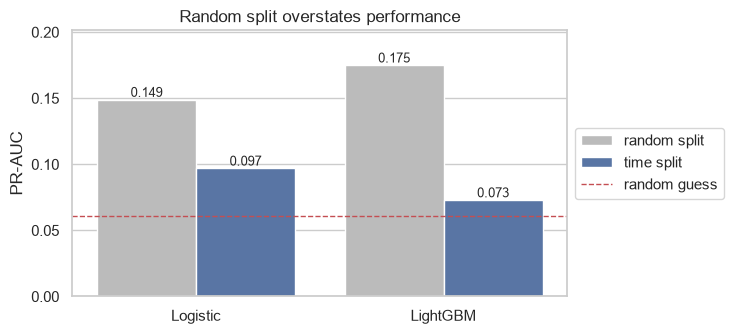

In [8]:
plot_df = pd.DataFrame({
    "모델": ["Logistic", "LightGBM"] * 2,
    "분할": ["random split"] * 2 + ["time split"] * 2,
    "PR-AUC": [float(split_cmp.iloc[0, 0].split(" ")[0]), float(split_cmp.iloc[1, 0].split(" ")[0]),
               result.loc["로지스틱 회귀", "test PR-AUC"], result.loc["LightGBM", "test PR-AUC"]],
})
fig, ax = plt.subplots(figsize=(7.5, 3.5))
sns.barplot(data=plot_df, x="모델", y="PR-AUC", hue="분할", palette=["#BBBBBB", "#4C72B0"], ax=ax)
ax.axhline(random_baseline, color="#C44E52", ls="--", lw=1, label="random guess")
ax.set_xlabel(""); ax.set_title("Random split overstates performance")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); ax.set_ylim(0, plot_df["PR-AUC"].max() * 1.15)
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_split_comparison.png", dpi=150)

**해석**
- 무작위 분할에서는 점수가 **로지스틱 약 1.5배, LightGBM 약 2.4배** 높게 나오고, LightGBM이 로지스틱보다 앞선다.
- 시간순 분할에서는 순서가 뒤집힌다. LightGBM의 test ROC-AUC는 0.54로 사실상 무작위에 가깝다.
- 이유: 무작위로 섞으면 학습 데이터에 **평가 시기와 같은 시기의 제품**이 들어간다. 같은 시기 제품끼리는 공정 조건이 비슷해서
  모델이 "시기"를 외워 맞힐 수 있다. 실제 라인에서는 미래 제품을 예측해야 하므로 이 점수는 부풀려진 것이다.
- **포트폴리오의 핵심 메시지**: 평가 방식을 현실에 맞게 설계하면 점수는 낮아지지만, 그 점수가 실제로 기대할 수 있는 성능이다.

## 요약 → 다음 단계

| 항목 | 결과 |
|---|---|
| 설정 선택 | 학습 데이터 안 시간순 교차검증 (PR-AUC 기준) |
| test PR-AUC | 위 표 참고. 두 모델 모두 무작위(약 0.06)보다 높지만 격차는 작음 |
| 모델 비교 | CV에서는 LightGBM 우세, test에서는 우위 사라짐 → 작은 데이터 + 시기 변화에서의 과적합 |
| 분할 비교 | 무작위 분할은 점수를 크게 부풀림 |

다음(04): 혼동행렬, 불량 재현율, 판정 기준(threshold) 정하기, 그리고 test 불량이 24개뿐인 만큼 점수의 신뢰구간을 계산한다.